# Aperture correction for a point source

A small aperture captures only a fraction of a point source's light. Because the PSF can vary with wavelength, this fraction can also change across a spectrum. A normalized PSF lets us estimate the missing light and recover an integrated flux density under the point-source assumption.

All three approaches below require a PSF model applicable to the observations. Here it is calibrated using an isolated field star with the same spatial sampling and wavelength convention. [Chromatic PSF](Chromatic%20PSF.ipynb) shows that calibration; a compact model is supplied so this example can run independently.

| Estimate | Operation | When useful / limitation |
| --- | --- | --- |
| `aperture` | Divide the aperture sum by the wavelength-dependent PSF fraction. | Corrects chromatic aperture losses; any extended emission inside the aperture is rescaled too. |
| `optimal` | Fit a fixed PSF amplitude and a constant background at each wavelength. | Minimum-variance linear estimate with a correct spatial model and known independent variances; unknown spatial structure can bias it. |
| Constant correction | Multiply the aperture sum by the mean PSF-derived correction. | Avoids transferring detailed chromatic fluctuations in the correction, but loses real chromatic variation. Still requires the PSF model. |

None of these methods guarantees separation of a point source from arbitrary surrounding emission.

## Workflow at a glance

**Inputs:** a flux-density cube with a variance cube, a normalized wavelength-dependent PSF calibrated from an isolated point source, and aperture/fit radii in pixels. The PSF must match the spatial sampling and cover the wavelengths to extract.

1. Load the cube and PSF; estimate a fixed source center from the mean image.
2. Define the small extraction aperture and the larger PSF-fitting region.
3. **Method 1:** extract, inspect and save the wavelength-dependent aperture correction.
4. **Method 2:** rescale the raw aperture spectrum from Method 1 by its mean correction.
5. **Method 3:** independently fit, inspect and save the PSF-plus-constant spectrum.
6. Compare the three spectra, statistical errors and correction factors.

**Outputs:** three spectra, diagnostic tables and a three-panel comparison. ECSV files preserve units and errors; the comparison is also saved as a PDF. Change the paths and radii below for another source.

In [1]:
%matplotlib inline

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling.models import Const2D
from IPython.display import display

from prism.data import Cube
from prism.utils.plotting import plot_outline
from prism.modeling.psf import fitimage, ChromaticPSF, aperture, optimal

In [2]:
cubepath = Path('data/pointsource.fits')
psfpath = Path('data/psf.fits')
outpath = Path('results/extraction')
outpath.mkdir(parents=True, exist_ok=True)

psf = ChromaticPSF.from_fits(psfpath)
cube = Cube.from_fits(cubepath, ext_values='DATA', ext_var='VAR')
img = cube.get_image(method='mean')
cy, cx = np.unravel_index(np.nanargmax(img.values), img.shape)
y, x = np.indices(img.shape)

## Fixed target center

Use `fitimage` to estimate the center once from the mean image, fixing the PSF shape to the calibration at a representative wavelength. Only centroid, amplitude and a local constant are fitted at this step. Subsequent extraction keeps the center and PSF shape fixed.

All radii below are in pixels. The aperture and fit masks select pixels by their centers.

In [3]:
model = psf(float(np.mean(psf.domain)))
for name in model.param_names:
    model.fixed[name] = name not in ('amplitude', 'x_0', 'y_0')
model.x_0, model.y_0 = float(cx), float(cy)
model.x_0.bounds = (cx-2, cx+2)
model.y_0.bounds = (cy-2, cy+2)
model.amplitude = float(img.values[cy, cx] - np.nanmedian(img.values))

initial = fitimage(img, model, mask=((x-cx)**2 + (y-cy)**2 <= 4**2),
                   background=Const2D(float(np.nanmedian(img.values))), factor=psf.factor)
assert initial['success'], initial['message']
center = (float(initial['y_0']), float(initial['x_0']))
print('Fixed center (y, x):', center)

Fixed center (y, x): (10.216819565726883, 10.021959670517251)


## Extraction regions

Define both pixel-center selections once: the small aperture for Methods 1 and 2, and the larger fit region for Method 3. Outlines follow the exact selected pixel edges.

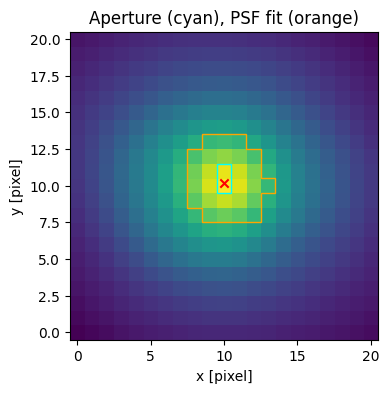

In [4]:
radius = 1.0
fitradius = 3.0
mask = (x-center[1])**2 + (y-center[0])**2 <= radius**2
fitmask = (x-center[1])**2 + (y-center[0])**2 <= fitradius**2
# Binary masks select pixels by their centers; these are not fractional circles.

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(np.arcsinh(img.values), origin='lower', cmap='viridis')
plot_outline(mask, ax=ax, color='cyan')
plot_outline(fitmask, ax=ax, color='orange')
ax.scatter(center[1], center[0], marker='x', color='red')
ax.set(xlabel='x [pixel]', ylabel='y [pixel]', title='Aperture (cyan), PSF fit (orange)')
plt.show()

## Method 1 — Wavelength-dependent aperture correction

Sum the small aperture and divide by the fraction of the normalized PSF captured by the same mask. The PSF is normalized on the infinite plane, so the finite-aperture fraction is not one. This retains any surrounding emission inside the aperture and rescales it too; prefer this composite spectrum when the surrounding morphology is unknown.

In [5]:
spectrum, diagnostics = aperture(cube, psf, mask, center=center)
print(f"Aperture: {np.count_nonzero(diagnostics['success'])}/{len(diagnostics)} valid channels")
print('Aperture pixels:', mask.sum())
display(diagnostics[['wave', 'fraction', 'success']][::200])
diagnostics.meta['source'] = str(cubepath)
diagnostics.meta['psf_source'] = str(psfpath)
diagnostics.write(outpath / 'aperture-spectrum.ecsv', overwrite=True)

Aperture: 3681/3681 valid channels
Aperture pixels: 2


wave,fraction,success
Angstrom,,
float64,float64,bool
4750.273437499998,0.08119972784988362,True
5000.273437499998,0.08583442624405933,True
5250.273437499997,0.08958558973503042,True
5500.273437499998,0.09248097150558618,True
5750.273437499998,0.09465749541322188,True
6000.273437499997,0.09629092106331733,True
6250.273437499997,0.09757377576364482,True
6500.273437499998,0.09871610076251305,True


## Method 2 — Constant aperture correction

Take the unweighted mean of the valid wavelength-dependent aperture corrections and apply it to the raw aperture spectrum. This factor still comes from the PSF model. It smooths away both spurious and real chromatic variations; it does not remove surrounding emission. The wavelength-dependent spread of the corrections is not, by itself, an uncertainty estimate.

This comparison reuses the raw aperture sum and PSF fractions from Method 1; it does not depend on Method 3.

In [6]:
correction = 1 / np.asarray(diagnostics['fraction'])
valid = np.asarray(diagnostics['success']) & np.isfinite(correction)
scale = float(np.mean(correction[valid]))
constant = diagnostics[['wave', 'rawflux', 'rawerr', 'success']].copy()
constant.rename_columns(['rawflux', 'rawerr'], ['flux', 'flux_err'])
constant['flux'] *= scale
constant['flux_err'] *= scale
constant.meta['method'] = 'constant aperture correction'
constant.meta['correction'] = scale
constant.meta['averaging'] = 'Unweighted mean of 1/fraction over valid channels'
constant.write(outpath / 'constant-spectrum.ecsv', overwrite=True)
print(f'Mean aperture correction: {scale:.4f}')

Mean aperture correction: 9.7242


## Method 3 — PSF + constant background (`optimal`)

Use the larger fit region to distinguish the fixed PSF profile from a spatially constant background. Only amplitude and background are fitted in each wavelength channel. The output already estimates the integrated PSF amplitude: no additional aperture correction is applied. Its minimum-variance interpretation requires a correct model and known independent variances; unknown compact, asymmetric or chromatic emission can bias the result.

In [7]:
fitted, fitinfo = optimal(cube, psf, fitmask, center=center, background=Const2D())
print(f"PSF fit: {np.count_nonzero(fitinfo['success'])}/{len(fitinfo)} valid channels")
print('PSF-fit pixels:', fitmask.sum())
display(fitinfo[['wave', 'background', 'redchi2', 'success']][::200])
fitinfo.meta['source'] = str(cubepath)
fitinfo.meta['psf_source'] = str(psfpath)
fitinfo.write(outpath / 'optimal-spectrum.ecsv', overwrite=True)

PSF fit: 3681/3681 valid channels
PSF-fit pixels: 28


wave,background,redchi2,success
Angstrom,1e-20 erg / (Angstrom s cm2),,
float64,float64,float64,bool
4750.273437499998,1660.3236984528419,14.113620966688094,True
5000.273437499998,896.8682120351529,20.657534111185985,True
5250.273437499997,926.9278968367473,22.540349559795384,True
5500.273437499998,1221.9046967925353,25.856382336626396,True
5750.273437499998,1341.2131034280505,22.838549463395477,True
6000.273437499997,1311.592940358571,35.23596904505053,True
6250.273437499997,1129.4596703032782,29.397519742782354,True
6500.273437499998,1128.1710928253642,23.620726339031005,True


## Compare spectra, errors and correction factors

The lower panel shows the PSF aperture correction, its constant mean, and the PSF-fit/raw-aperture flux ratio. The last quantity is diagnostic: background subtraction and different spatial weights also affect it.

For a fixed correction $C$, the propagated measurement error is $\sigma_F=C\,\sigma_S$, where $S$ is the raw aperture sum. These are conditional statistical errors. Uncertainty in the calibrated PSF can contribute both statistical calibration uncertainty and model systematics, correlated across wavelength; it is not included here. Neither the spread of $C(\lambda)$ nor the difference between extraction methods should simply be added as independent noise to each channel. Inter-spaxel covariance is also omitted.

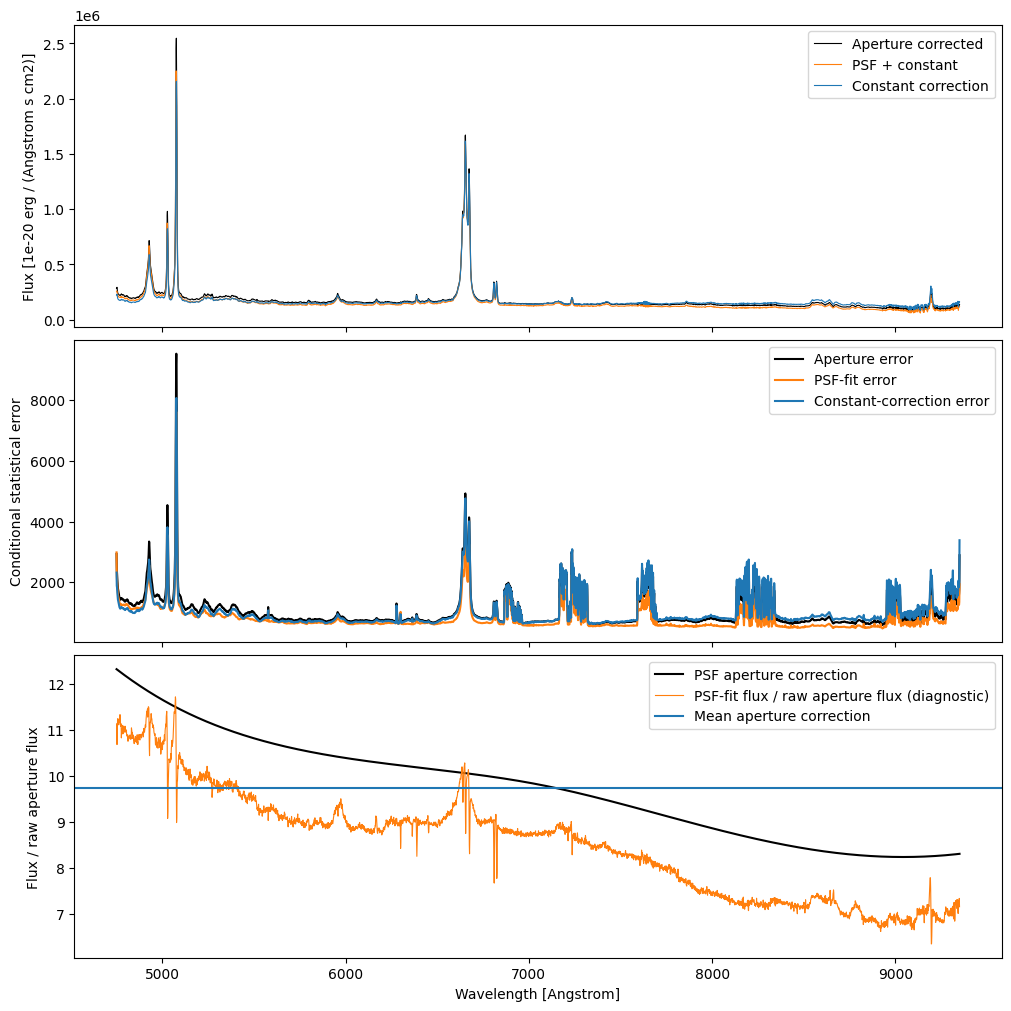

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, constrained_layout=True)
axes[0].plot(spectrum.x, spectrum.y, label='Aperture corrected', color='black', lw=.8)
axes[0].plot(fitted.x, fitted.y, label='PSF + constant', color='tab:orange', lw=.8)
axes[0].plot(spectrum.x, constant['flux'], label='Constant correction', color='tab:blue', lw=.8)
axes[0].set_ylabel(f'Flux [{cube.unit}]')
axes[0].legend()
axes[1].plot(spectrum.x, spectrum.yerr, color='black', label='Aperture error')
axes[1].plot(fitted.x, fitted.yerr, color='tab:orange', label='PSF-fit error')
axes[1].plot(spectrum.x, constant['flux_err'], color='tab:blue', label='Constant-correction error')
axes[1].set_ylabel('Conditional statistical error')
axes[1].legend()

# The fitted flux / raw aperture flux is diagnostic, not a PSF-only correction:
# optimal uses different spatial weights and fits an additive background.
raw = np.asarray(diagnostics['rawflux'])
ratio = np.full(raw.shape, np.nan)
valid = np.asarray(fitinfo['success']) & np.asarray(diagnostics['success']) & np.isfinite(raw) & (raw != 0)
np.divide(fitted.y, raw, out=ratio, where=valid)
axes[2].plot(spectrum.x, correction, color='black', label='PSF aperture correction')
axes[2].plot(spectrum.x, ratio, color='tab:orange', lw=.8, label='PSF-fit flux / raw aperture flux (diagnostic)')
axes[2].axhline(scale, color='tab:blue', label='Mean aperture correction')
axes[2].set(xlabel=f'Wavelength [{cube.zunit}]', ylabel='Flux / raw aperture flux')
axes[2].legend()
fig.savefig(outpath / 'extraction-comparison.pdf')
plt.show()

Differences between the spectra can reflect spatial weighting, background assumptions or PSF mismatch. Repeat with different aperture and fit radii to assess sensitivity; this is a robustness check, not a calibrated uncertainty. The plotted errors alone do not quantify these effects. Physical interpretations, including luminosity estimates, must account for any surrounding emission retained in the chosen spectrum.

## Reuse the results

The ECSV files retain wavelength and flux units, statistical errors, success flags and diagnostics. The compact PSF can be reloaded independently of the star cube. Keep the same pixel scale and remain within `psf.domain`.

In [9]:
# from astropy.table import Table
# result = Table.read('results/extraction/aperture-spectrum.ecsv')
# psf = ChromaticPSF.from_fits('data/psf.fits')
# image = psf.get_image(6500, (21, 21), center=center)  # Bare wavelength uses psf.unit.